# IsoFormer: GTEx data and input checks

What would the released GTEx table actually supply to IsoFormer, and how would preparation choices change the transcripts used to train and compare it? This notebook follows a transcript row from its expression targets and supplied inputs through annotation, partition, length and genomic-window checks. It measures the consequences of possible rules; it does not adopt a training protocol or fit a model.

Three sets need to stay distinct. The **released table** contains all source rows. A candidate **experiment population**, or cohort, contains the transcript IDs admitted by specified input rules, such as requiring extractable genomic DNA. Within an experiment, admitted transcripts occupy **training, validation and test partitions**, used respectively to fit parameters, select settings or checkpoints, and evaluate the selected model. Filtering inputs does not itself move rows between the raw partitions. A source-row count is therefore not a training-set count. Here, choosing a cohort specifically means deciding which released GTEx transcripts remain eligible, including whether transcripts without a supplied protein can participate.

The investigation follows **one transcript and its targets → supplied inputs and annotations → separation between partitions → sequence preparation → who each policy affects → decisions for reproduction**. The [Enformer reference notebook](tier2_isoformer_reproduction.ipynb) owns model construction, forward checks and eventual training. The [frozen GTEx pilot](tier2_lucaone_isoformer.ipynb) is a separate earlier experiment.


**Reading route.** `read_results` builds tables and figures from a selected completed JSON; no CSV or network access is needed. The two earlier JSONs remain readable as explicit fallbacks, but they do not contain the added annotation, overlap, target and policy-group checks. An unavailable section is reported as **not measured**, never filled with zeros or inferred from a different record. Existing saved outputs retain their previous execution provenance until rerun.

A full measurement uses `run_audit` and the repository's deterministic code. It collects the added checks in the same CSV pass as the length counts and saves a separate completed JSON. The local `GTEx_pilot.csv` cannot replace this source because it is a selected subset; see the [pilot builder](../stage1/build_gtex_pilot.py).

---

## Setup

Use the repository [notebook environment](../../README.md#notebook-dependencies). Reading the retained audit uses ordinary data/display packages. Recomputing token counts also uses Transformers' local `EsmTokenizer` class with two small, verified vocabulary files; it does not execute remote model code.

This audit uses the CPU. A fresh run reads a 644.6 MB CSV and holds count summaries rather than embedding arrays. Download speed and tokenization affect duration; no portable runtime estimate has been established.

In [1]:
# Paths, source identity, temporary downloads and execution timestamps.
import hashlib
import importlib
import platform
import sys
import tempfile
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

# Tables and plotting. Import NumPy before a deferred Transformers import.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
# Resolve the checkout whether Jupyter starts here, in Code/, or at its root.
REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Code" / "shared_code").is_dir()),
    None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the repository.")

CODE_DIR = REPO_ROOT / "Code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from shared_code.fusion import isoformer_data_checks as gtex_checks
from shared_code.fusion import isoformer_cohort as cohort

# Refresh both stateless helpers when setup is rerun after repository edits.
gtex_checks = importlib.reload(gtex_checks)
cohort = importlib.reload(cohort)

### Read saved results or measure the full table

Use `AUDIT_MODE = "read_results"` for ordinary reading. Choose `"run_audit"` to measure the pinned CSV and save the expanded report. Neither mode loads model weights or trains anything.

| Mode | Inputs and effect |
| --- | --- |
| `read_results` | Read `RESULT_PATH`; if absent, try the explicitly named previous notebook record, then the historical reference. Display the chosen record and missing sections. No newest-file search or automatic audit. |
| `run_audit` | Verify `CSV_PATH` if present; otherwise use a temporary download. Measure the full table, including the added data checks, and save the completed report at `RESULT_PATH`. |

`gtex_audit_v2.json` identifies the expanded analysis, while `cohort_audit.json` and the original historical JSON retain their existing evidence. An identical rerun preserves the saved file and its original provenance. Changed identity or measurements require a deliberately different output path; completed records are not overwritten or merged.

Downloaded inputs are temporary files on disk, not RAM-only copies. They are removed on exit; an existing local CSV is preserved. The large CSV remains outside Git. The JSON supplies the figures directly, so no separate image files are required.

In [33]:
AUDIT_MODE = "run_audit"  # "read_results" or "run_audit"

# A full local CSV is optional; the smaller GTEx_pilot.csv is not a substitute.
CSV_PATH = REPO_ROOT / ".data-cache" / "GTEx_final.csv"
RESULT_DIR = CODE_DIR / "stage4" / "results" / "isoformer_cohort_audit"
RESULT_PATH = RESULT_DIR / "gtex_audit_v2.json"

# Named predecessors remain valid evidence but lack the added data-check sections.
PREVIOUS_RECORD = RESULT_DIR / "cohort_audit.json"
HISTORICAL_RECORD = RESULT_DIR / "full_csv_2026-11-09.json"

In [34]:
DATASET_REVISION = "330ab1795abca683e692c7ee138a2e89c0c882f1"
MODEL_REVISION = "afac2a386c8f2241faf8fad3c5971a9307c13775"
CSV_SHA256 = "99f86bb787cc37b7b016ed7ec1dc49aacaa5605a4679b7ddff1e8c090f7667fd"
CSV_BYTES = 644_594_050

CSV_URL = (
    "https://huggingface.co/datasets/InstaDeepAI/"
    f"multi_omics_transcript_expression/resolve/{DATASET_REVISION}"
    "/transcript_expression/GTEx_final.csv"
)
VOCAB_ROOT = (
    f"https://huggingface.co/InstaDeepAI/isoformer/resolve/{MODEL_REVISION}"
)
VOCAB_SHA256 = {
    "rna": "c00e0ad166d6ab3f7540ebc92270392e581bb3106763412f29034b49323e1052",
    "protein": "0f32181752cb8dd5766f8fa6dc0adb69d56df3fc7db1135e7006feeab3c0b8d7",
}
CHROMOSOME_URL = (
    "https://hgdownload.soe.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes"
)
CHROMOSOME_SHA256 = (
    "e1d9152418038457a959e949d99c9caf7ae3e4f87cfbb4ffe7d8b9a54ba1202b"
)

SOURCE_IDENTITY = {
    "source_sha256": CSV_SHA256,
    "source_bytes": CSV_BYTES,
    "dataset_revision": DATASET_REVISION,
    "model_revision": MODEL_REVISION,
    "vocabulary_sha256": VOCAB_SHA256,
    "chromosome_sizes_sha256": CHROMOSOME_SHA256,
    "method_version": cohort.METHOD_VERSION,
    "data_checks_version": cohort.DATA_CHECKS_VERSION,
}
PREVIOUS_IDENTITY = {
    key: value for key, value in SOURCE_IDENTITY.items()
    if key != "data_checks_version"
}
LEGACY_IDENTITY = {
    key: value for key, value in PREVIOUS_IDENTITY.items()
    if key != "method_version"
}

## What the sources establish

The paper describes the experiment; a dataset card describes a dataset version; the CSV supplies rows; a loader prepares examples; an inference wrapper computes predictions. These are related evidence, but none alone supplies the missing original training pipeline.

| Evidence | Supported observation | Remaining limitation |
| --- | --- | --- |
| [Final paper, §§4.2–4.4 and Appendix A](https://proceedings.neurips.cc/paper_files/paper/2024/file/8f6b3692297e49e5d5c91ba00281379c-Paper-Conference.pdf) | Roughly 170k transcripts, roughly 90k protein-coding; gene-separated train/test; absent-modality cross-attention can be zeroed. | No recovered per-condition transcript manifest or complete missing/overlength-protein admission rule. |
| [Dataset card](https://huggingface.co/datasets/InstaDeepAI/multi_omics_transcript_expression/blob/330ab1795abca683e692c7ee138a2e89c0c882f1/README.md) | Describes coding genes and totals 91,241 transcripts. | Predates the expanded CSV; its partition counts differ from the pinned CSV's protein-present rows. |
| [Current file metadata](https://huggingface.co/api/datasets/InstaDeepAI/multi_omics_transcript_expression/tree/330ab1795abca683e692c7ee138a2e89c0c882f1/transcript_expression?expand=true) and [Historical file metadata](https://huggingface.co/api/datasets/InstaDeepAI/multi_omics_transcript_expression/tree/ce68d96a7bd99db9f543e2cf3c9be57d8253b93d/transcript_expression?expand=true) | Current CSV and the historical fixed TPM CSV have the same file hash. | File identity does not identify the later trainer's row selection. |
| [Released loader](https://huggingface.co/datasets/InstaDeepAI/multi_omics_transcript_expression/blob/330ab1795abca683e692c7ee138a2e89c0c882f1/multi_omics_transcript_expression.py) | Passes protein fields through; applies genomic-window rules; named validation selects raw test. | No explicit missing/overlength-protein selector; the unused raw `eval` label is not automatically our validation set. |
| [Released model](https://huggingface.co/InstaDeepAI/isoformer/blob/afac2a386c8f2241faf8fad3c5971a9307c13775/modeling_isoformer.py#L87) | Always executes the protein branch and protein cross-attention. | No recovered per-row missing-protein zeroing branch. Empty strings or padding are not established substitutes. |
| [Official inference notebook](https://github.com/instadeepai/nucleotide-transformer/blob/123c50144df3a5332bc96593da7e35f32b394595/notebooks/isoformer/inference.ipynb) | Demonstrates tokenization and inference on a test example. | It is not the training collator or a cohort-construction script. |

**Why this gap matters.** The paper's broader transcript task includes absent-modality handling that the released wrapper does not expose. That gap calls for an explicit reconstruction; it does not show that the authors discarded transcripts without proteins. The availability section develops the proposed approach.

The [source record](../../docs/sources.md#isoformer-dataset-and-model-cards) and [reference specification](RUNBOOK.md#sequence-lengths-in-the-released-path) retain the wider review; the executable counts below establish different, directly checkable facts.

Downloads use the explicit commit revisions in the settings, not the moving `main` branch, and verify file hashes. A later online update does not silently change this analysis. Adopting another release requires updating its declared identity and keeping its results separate. Source-review dates belong in the linked source record; execution dates are read from the selected JSON.

---

## Obtain a verified audit

The following functions define the optional measurement path. Defining them makes no network requests. In `run_audit`, absent inputs are downloaded into a temporary directory on disk and checked before use; the Hugging Face model cache is not used. A present but mismatched local CSV fails verification rather than being overwritten.

The completed result records its own inputs, counting-method version, tokenizer version, host and execution timestamps. Saving is separate from measurement: only a completed, validated report can become the named JSON.

In [35]:
def download_verified(url, destination, expected_sha256, expected_bytes=None):
    """Fetch a declared public source into caller-owned temporary storage."""
    digest = hashlib.sha256()
    size = 0
    with urllib.request.urlopen(url, timeout=60) as response:
        with destination.open("wb") as handle:
            while block := response.read(4 * 1024 * 1024):
                handle.write(block)
                digest.update(block)
                size += len(block)
    if digest.hexdigest() != expected_sha256:
        raise ValueError(f"Source hash mismatch: {url}")
    if expected_bytes is not None and size != expected_bytes:
        raise ValueError(f"Source size mismatch: {size} != {expected_bytes}")
    return destination

In [36]:
def local_tokenizers(directory):
    """Use released vocabularies with a local library class, never a model."""
    import transformers
    from transformers import EsmTokenizer

    paths = {}
    for modality, expected_hash in VOCAB_SHA256.items():
        paths[modality] = download_verified(
            f"{VOCAB_ROOT}/{modality}_vocab_list.txt",
            directory / f"{modality}_vocab_list.txt",
            expected_hash,
        )
    rna = EsmTokenizer(str(paths["rna"]), model_max_length=1024)
    rna.eos_token = None  # The released RNA wrapper adds CLS, but no EOS.
    rna.init_kwargs["eos_token"] = None
    protein = EsmTokenizer(str(paths["protein"]), model_max_length=1024)
    return rna, protein, transformers.__version__

In [37]:
def repeat_audit(source_path):
    """Measure verified input; remove only this call's temporary downloads."""
    started = datetime.now(timezone.utc).isoformat()
    with tempfile.TemporaryDirectory(prefix="isoformer-gtex-") as workspace:
        directory = Path(workspace)
        if not source_path.exists():
            source_path = download_verified(
                CSV_URL, directory / "GTEx_final.csv", CSV_SHA256, CSV_BYTES
            )
        elif not source_path.is_file():
            raise ValueError(f"CSV_PATH must identify a file: {source_path}")

        rna_tokenizer, protein_tokenizer, version = local_tokenizers(directory)
        chromosome_path = download_verified(
            CHROMOSOME_URL, directory / "hg38.chrom.sizes", CHROMOSOME_SHA256
        )
        chromosome_sizes = {
            name: int(size)
            for name, size in (
                line.split() for line in chromosome_path.read_text().splitlines()
            )
        }
        measured = cohort.audit_csv(
            source_path, rna_tokenizer, protein_tokenizer,
            expected_sha256=CSV_SHA256, expected_bytes=CSV_BYTES,
            chromosome_sizes=chromosome_sizes, include_data_checks=True,
        )

    measured.update({
        "started_utc": started,
        "finished_utc": datetime.now(timezone.utc).isoformat(),
        "source_url": CSV_URL,
        "dataset_revision": DATASET_REVISION,
        "model_revision": MODEL_REVISION,
        "transformers": version,
        "python": sys.version,
        "host": platform.node(),
        "implementation_sha256": hashlib.sha256(Path(cohort.__file__).read_bytes()).hexdigest(),
        "data_checks_implementation_sha256": hashlib.sha256(
            Path(gtex_checks.__file__).read_bytes()
        ).hexdigest(),
        "vocabulary_sha256": VOCAB_SHA256,
        "chromosome_sizes_sha256": CHROMOSOME_SHA256,
        "audit_identity": {**SOURCE_IDENTITY, "transformers": version},
    })
    return measured

In [38]:
if AUDIT_MODE not in {"read_results", "run_audit"}:
    raise ValueError("AUDIT_MODE must be read_results or run_audit.")

if AUDIT_MODE == "read_results":
    # Explicit predecessors, not a newest-file search or a fallback after corruption.
    selected_path = next(
        (path for path in (RESULT_PATH, PREVIOUS_RECORD, HISTORICAL_RECORD)
         if path.exists()), RESULT_PATH,
    )
    if not selected_path.is_file():
        raise FileNotFoundError(
            f"No completed audit at {selected_path}. Use run_audit to create RESULT_PATH."
        )
    using_historical = selected_path == HISTORICAL_RECORD
    expected_identity = (
        LEGACY_IDENTITY if using_historical else
        PREVIOUS_IDENTITY if selected_path == PREVIOUS_RECORD else SOURCE_IDENTITY
    )
    audit = cohort.read_audit(
        selected_path, expected_identity=expected_identity,
        allow_legacy=using_historical,
    )
    evidence_kind = (
        "Historical reference" if using_historical else
        "Previous notebook audit" if selected_path == PREVIOUS_RECORD else
        "Expanded GTEx audit"
    )
else:
    protected_paths = {PREVIOUS_RECORD.resolve(), HISTORICAL_RECORD.resolve()}
    if RESULT_PATH.resolve() in protected_paths:
        raise ValueError("RESULT_PATH must not replace a preserved previous audit.")
    if RESULT_PATH.exists():
        cohort.read_audit(RESULT_PATH, expected_identity=SOURCE_IDENTITY)
    measured_audit = repeat_audit(CSV_PATH)
    created = cohort.save_audit(RESULT_PATH, measured_audit)
    print("Saved completed audit." if created else
          "Measurements match; the original file and provenance were retained.")
    selected_path = RESULT_PATH
    audit = cohort.read_audit(RESULT_PATH, expected_identity=SOURCE_IDENTITY)
    evidence_kind = "Expanded GTEx audit"

print(f"{evidence_kind}: {selected_path}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (2001 > 1024). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1025 > 1024). Running this sequence through the model will result in indexing errors


Saved completed audit.
Expanded GTEx audit: d:\academic\UCF\2026_fall\Capstone Project CAP6942\Research\genomics-multimodal-fusion\Code\stage4\results\isoformer_cohort_audit\gtex_audit_v2.json


In [39]:
display(pd.Series({
    "rows scanned": audit["row_count"],
    "unique transcript IDs": audit["unique_transcript_ids"],
    "duplicate transcript IDs": audit["duplicate_transcript_ids"],
    "source SHA-256": audit["source_sha256"],
    "started UTC": audit["started_utc"],
    "finished UTC": audit["finished_utc"],
    "host": audit.get("host", "not recorded"),
    "counting method": audit.get("audit_identity", {}).get("method_version", "historical script"),
    "expanded checks": audit.get("data_checks", {}).get("version", "not measured"),
    "Transformers": audit["transformers"],
}, name="Selected result provenance").to_frame())

,Selected result provenance
rows scanned,178215
unique transcript IDs,178215
duplicate transcript IDs,0
source SHA-256,99f86bb787cc37b7b016ed7ec1dc49aacaa5605a4679b7...
started UTC,2026-11-09T11:27:06.782168+00:00
finished UTC,2026-11-09T11:33:43.642467+00:00
host,cDesktopLab
counting method,isoformer-cohort-v1-exact-markers
expanded checks,gtex-data-checks-v1
Transformers,5.15.1


In [40]:
data_checks = audit.get("data_checks")
if data_checks is None:
    print(
        "This completed record predates the expanded GTEx checks. "
        "Existing counts remain available; new sections are unmeasured, not zero. "
        "Use run_audit explicitly to save the expanded result."
    )
else:
    print(f"Expanded measurements: {data_checks['version']}")


Expanded measurements: gtex-data-checks-v1


---
## What one row asks the model to predict

One row represents a transcript and its expression targets across 30 human tissues. Several transcripts can belong to one gene. Their RNA sequences and available protein sequences need not all differ: alternative transcripts can share a protein while differing in untranslated regions. Genomic coordinates support constructing the DNA input; they are not a DNA sequence already stored in this CSV.

The examples below retain identifiers, annotation and lengths, rather than printing entire sequences. They are the first recorded rows, not a random sample or a representative estimate of the population. A missing protein length means the audit found no supplied protein under its stated missing-marker rule. The [GTEx target explanation](../../docs/methods/data-and-targets.md#gtex-tissue-expression-labels) connects these rows to the assay.


In [41]:
if data_checks is not None:
    display(pd.DataFrame(data_checks["representative_rows"]["first_rows"]))
else:
    print("Row examples were not recorded in the selected result.")


,Protein_length,Protein_tokens,RNA_length,RNA_tokens,annotation,cds_present,gene_id,protein_id_present,row_number,split,transcript_id
0,None,None,1657,278,lnc_RNA,False,ENSG00000223972.5,False,1,train,ENST00000456328.2
1,None,None,712,123,lnc_RNA,False,ENSG00000243485.5,False,2,train,ENST00000473358.1
2,None,None,535,91,lnc_RNA,False,ENSG00000243485.5,False,3,train,ENST00000469289.1
3,None,None,1187,203,lnc_RNA,False,ENSG00000237613.2,False,4,train,ENST00000417324.1
4,None,None,590,101,lnc_RNA,False,ENSG00000237613.2,False,5,train,ENST00000461467.1


### Are the tissue targets usable in their stored form?

The target is transcript abundance in each tissue, rather than protein production or a classification of transcript type. The paper describes tissue-averaged transcript abundance and a log transformation, followed by tissue normalization for its experiment. The released dataset card describes log-transformed labels; its loader returns the stored values and normalization statistics separately. Those sources do not establish that applying those statistics to these labels is appropriate. This audit therefore reads the **stored numbers unchanged**. [Paper, Appendices A–B](https://proceedings.neurips.cc/paper_files/paper/2024/file/8f6b3692297e49e5d5c91ba00281379c-Paper-Conference.pdf#page=16), [pinned dataset card](https://huggingface.co/datasets/InstaDeepAI/multi_omics_transcript_expression/blob/330ab1795abca683e692c7ee138a2e89c0c882f1/README.md), [released loader](https://huggingface.co/datasets/InstaDeepAI/multi_omics_transcript_expression/blob/330ab1795abca683e692c7ee138a2e89c0c882f1/multi_omics_transcript_expression.py).

The check separates missing columns, blank cells, nonnumeric text, and nonfinite numbers such as NaN or infinity. A finite zero is a valid stored number, not a missing field or proof that a transcript can never be expressed. Negative values are reported because they need explanation under the stated log-of-nonnegative-abundance interpretation.


In [42]:
if data_checks is not None:
    targets = data_checks["targets"]
    display(pd.Series({
        "expected tissue columns": len(targets["expected_order"]),
        "missing columns": targets["missing_columns"],
        "matches released tissue order": targets["order_matches"],
        "observed order": targets["observed_order"],
    }, name="Target schema").to_frame())
    target_table = pd.DataFrame.from_dict(targets["columns"], orient="index")
    target_table.index.name = "tissue"
    display(target_table)
else:
    print("Tissue schema and numeric checks were not recorded in the selected result.")


,Target schema
expected tissue columns,30
missing columns,[]
matches released tissue order,True
observed order,"[Adipose Tissue, Adrenal Gland, Bladder, Blood..."


,finite,max,mean,min,missing,negative,nonfinite,nonnumeric,present,rows,variance,zero
tissue,,,,,,,,,,,,
Adipose Tissue,178215,13.355211,2.082959,0.0,0,0,0,0,True,178215,4.639085,6824
Adrenal Gland,178215,14.298560,2.002142,0.0,0,0,0,0,True,178215,4.588183,11117
Bladder,178215,13.307293,2.067483,0.0,0,0,0,0,True,178215,4.646992,26531
Blood,178215,15.434690,1.783832,0.0,0,0,0,0,True,178215,4.183010,8141
Blood Vessel,178215,12.861800,2.003596,0.0,0,0,0,0,True,178215,4.554382,7009
Brain,178215,14.572473,2.012798,0.0,0,0,0,0,True,178215,4.476851,5064
Breast,178215,13.386458,2.140067,0.0,0,0,0,0,True,178215,4.653883,8090
Cervix Uteri,178215,12.464368,2.112410,0.0,0,0,0,0,True,178215,4.711857,26983
Colon,178215,13.886893,2.096696,0.0,0,0,0,0,True,178215,4.654639,7309


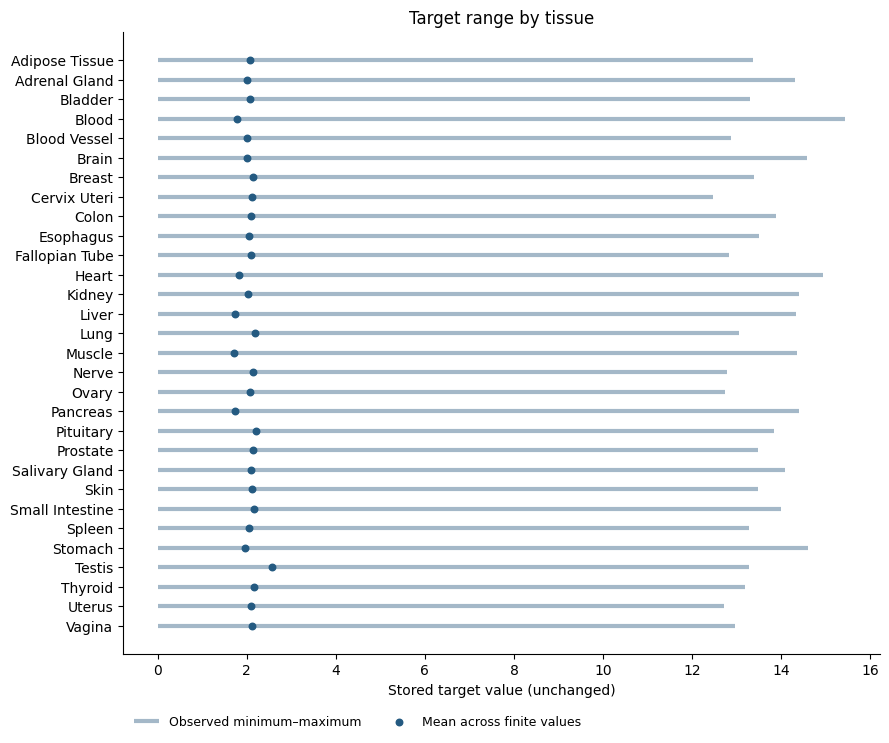

In [43]:
if data_checks is not None:
    # Ranges and means describe stored values; no target transformation is fitted.
    finite_targets = target_table.loc[target_table["finite"] > 0]
    if finite_targets.empty:
        print("No finite tissue values are available for a range plot.")
    else:
        y = np.arange(len(finite_targets))
        fig, ax = plt.subplots(figsize=(9, max(3, len(finite_targets) * 0.25)))
        ax.hlines(y, finite_targets["min"], finite_targets["max"],
                  color="#A4B8C8", linewidth=3, label="Observed minimum–maximum")
        ax.scatter(finite_targets["mean"], y, color="#245A81",
                   s=22, label="Mean across finite values", zorder=3)
        ax.set(yticks=y, yticklabels=finite_targets.index,
               xlabel="Stored target value (unchanged)", title="Target range by tissue")
        ax.invert_yaxis()
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08),
                  ncol=2, fontsize=9)
        fig.tight_layout()
        plt.show()


**Interpretation.** Each line spans the smallest to largest finite stored target for one tissue; its dot is the mean across transcripts. These are target distributions, not prediction scores or uncertainty intervals. Missing or nonfinite targets require an explicit training policy. A constant target has no within-tissue variation for a correlation to explain. Wide ranges help identify tissues whose scale could matter for the loss and normalization decision.

The next question concerns the inputs paired with those expression targets: whether an absent protein accompanies a particular transcript annotation, a CDS, or a protein-associated transcript identifier.


## What each transcript supplies

The inputs paired with each transcript's expression targets are its RNA, a protein when available, annotation/mapping fields and coordinates for extracting genomic DNA.

First compare raw partitions and protein availability. Repeated rows remain counted and are reported; missing fields are kept separate from length distributions and never converted into a literal `"nan"` protein. A missing protein can be consistent with noncoding annotation, or indicate an unresolved mapping. The following annotation check makes that distinction inspectable without inventing a biological label.

Missing fields are recognized under a declared marker rule. The [earlier-audit comparison](#Compare-with-the-earlier-local-audit) explains its difference from the original script.

In [44]:
coverage_rows = []
for split, row_count in audit["splits"].items():
    scope = audit["scopes"][f"split:{split}"]
    supplied = scope["stats"].get("Protein_length", {}).get("n", 0)
    coverage_rows.append({
        "raw split": split,
        "transcript rows": row_count,
        "protein supplied": supplied,
        "protein missing": row_count - supplied,
        "protein supplied (%)": 100 * supplied / row_count,
    })
coverage = pd.DataFrame(coverage_rows).set_index("raw split")
display(coverage.round(2))
display(pd.Series(audit["missing_sequences"], name="missing sequence fields").to_frame())

,transcript rows,protein supplied,protein missing,protein supplied (%)
raw split,,,,
eval,9120,4656,4464,51.05
test,8556,4363,4193,50.99
train,160539,82222,78317,51.22


,missing sequence fields
Protein,86974
RNA,0


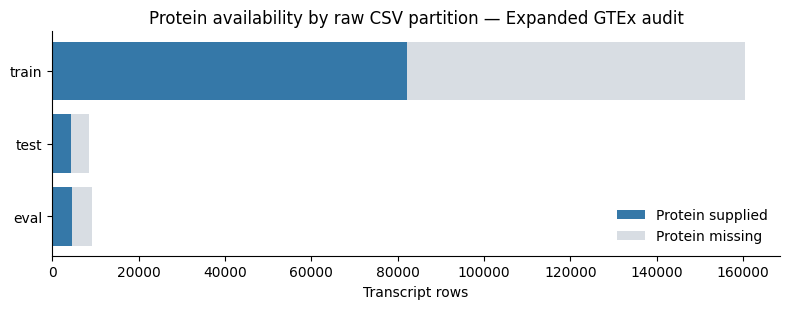

In [45]:
# These bars describe source coverage, not training progress or model quality.
positions = np.arange(len(coverage))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(positions, coverage["protein supplied"], color="#3578A8", label="Protein supplied")
ax.barh(
    positions, coverage["protein missing"], left=coverage["protein supplied"],
    color="#D8DDE3", label="Protein missing",
)
ax.set(yticks=positions, yticklabels=coverage.index, xlabel="Transcript rows")
ax.set_title(f"Protein availability by raw CSV partition — {evidence_kind}")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### What accompanies an absent protein?

To distinguish annotation-consistent absence from a possible mapping problem, we cross-tabulate the CSV's exact `RNA_type_gff` labels with protein, protein-associated transcript identifier (`transcript_id_ensembl_protein`) and CDS availability. The annotation is source evidence, not a biological classification inferred by this notebook. An available CDS or associated identifier alongside a missing protein is a useful row to inspect; it is not automatically a reason to delete that row. The shortened `protein_id` labels in the tables refer to that source field, not a verified protein accession.

The complete table retains every annotation. The figure shows the largest annotation groups by row count, with any smaller groups explicitly combined for display only.


In [46]:
if data_checks is not None:
    annotation_table = pd.DataFrame.from_dict(
        data_checks["annotations"]["by_type"], orient="index"
    ).sort_values("rows", ascending=False)
    annotation_table.index.name = "raw RNA_type_gff"
    display(annotation_table)
else:
    print("Annotation and sequence-availability cross-tabs were not recorded.")


,cds_missing,cds_present,missing_protein_with_cds,missing_protein_with_id,protein_id_missing,protein_id_present,protein_missing,protein_present,rna_missing,rna_present,rows
raw RNA_type_gff,,,,,,,,,,,
mRNA,0,91241,0,0,0,91241,0,91241,0,91241,91241
lnc_RNA,56229,0,0,0,56229,0,56229,0,0,56229,56229
transcript,25902,0,0,0,25902,0,25902,0,0,25902,25902
snRNA,1905,0,0,0,1905,0,1905,0,0,1905,1905
miRNA,1877,0,0,0,1877,0,1877,0,0,1877,1877
snoRNA,941,0,0,0,941,0,941,0,0,941,941
scRNA,50,0,0,0,50,0,50,0,0,50,50
rRNA,48,0,0,0,48,0,48,0,0,48,48
tRNA,22,0,0,0,22,0,22,0,0,22,22


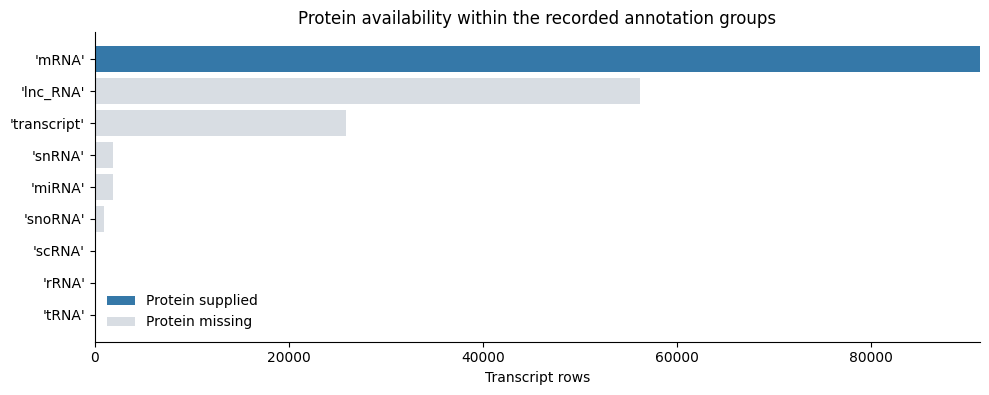

In [47]:
if data_checks is not None and not annotation_table.empty:
    plot_annotations = annotation_table[["protein_present", "protein_missing"]].copy()
    plot_labels = [repr(label) for label in plot_annotations.index[:12]]
    if len(plot_annotations) > 12:
        tail = plot_annotations.iloc[12:].sum().to_frame().T
        plot_annotations = pd.concat([plot_annotations.iloc[:12], tail])
        plot_labels.append("Other raw annotations (combined)")
    y = np.arange(len(plot_annotations))
    fig, ax = plt.subplots(figsize=(10, max(3, len(plot_annotations) * 0.45)))
    ax.barh(y, plot_annotations["protein_present"], color="#3578A8",
            label="Protein supplied")
    ax.barh(y, plot_annotations["protein_missing"],
            left=plot_annotations["protein_present"], color="#D8DDE3",
            label="Protein missing")
    ax.set(yticks=y, yticklabels=plot_labels, xlabel="Transcript rows",
           title="Protein availability within the recorded annotation groups")
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


**Interpretation.** Read the source annotation together with the sequence and mapping fields. An explicit noncoding annotation supports interpreting an absent protein as expected for that transcript; a generic `transcript` label does not establish the same biology. A protein missing despite a supplied CDS or associated identifier would raise a different mapping question. These distinctions prevent treating every absence as damaged data or assigning a biological label from a blank field alone.

Restricting the experiment to protein-supplied transcripts would change which kinds of transcripts the model learns to predict. That is a cohort choice, not simply routine removal of incomplete rows.


### How could a transcript without protein enter IsoFormer?

The expression target belongs to the RNA transcript, so the task remains meaningful when no protein sequence is supplied. Following the paper's absent-modality description, the approach below is a **proposed reconstruction, not yet adopted or implemented**. [Paper, §4.2](https://proceedings.neurips.cc/paper_files/paper/2024/file/8f6b3692297e49e5d5c91ba00281379c-Paper-Conference.pdf).

In the selected released architecture, DNA first attends to RNA, then receives a protein-derived update through a residual addition. The proposal would make that second update conditional on protein availability:

$$
H_{\mathrm{final},i} = H_{\mathrm{DNA+RNA},i} + m_i\,\Delta_{\mathrm{protein},i}.
$$

**In this notation:**

- $i$ identifies one transcript row.
- $H_{\mathrm{DNA+RNA},i}$ is the matrix of DNA-position representations after RNA cross-attention.
- $\Delta_{\mathrm{protein},i}$ is the complete projected protein attention update, with the same shape as $H_{\mathrm{DNA+RNA},i}$.
- $m_i$ is a recorded availability indicator: 1 for a supplied protein, 0 for an absent protein under the declared source-field rule. It is not a learned gate or a biological noncoding classifier.
- $H_{\mathrm{final},i}$ is the representation passed to the same DNA pooling and prediction head.

**Interpretation.** A supplied protein contributes its released attention update. Without one, the transcript retains its RNA-updated DNA representation and can still supply an expression target for training the DNA/RNA path and prediction head. Other agreed input rules would determine its eligibility.

The [missing-protein implementation path](tier2_isoformer_reproduction.ipynb#Handling-missing-proteins) explains the complete-update bypass, batching and verification requirements. The dataset card offers a separate clue about historical population counts next.


### Does the historical card identify the same cohort?

The [card](https://huggingface.co/datasets/InstaDeepAI/multi_omics_transcript_expression/blob/330ab1795abca683e692c7ee138a2e89c0c882f1/README.md) lists 82,205 training, 4,718 test and 4,318 evaluation transcripts. We compare those counts with the current CSV's protein-supplied group, keeping the raw `eval` name distinct from a chosen validation policy.

In [48]:
card_counts = pd.Series(
    {"train": 82_205, "test": 4_718, "eval": 4_318},
    name="historical card",
)
card_comparison = pd.concat(
    [card_counts, coverage["protein supplied"].rename("current protein supplied")],
    axis=1,
)
card_comparison["difference"] = (
    card_comparison["current protein supplied"] - card_comparison["historical card"]
)
card_comparison.loc["total"] = card_comparison.sum()
display(card_comparison)

,historical card,current protein supplied,difference
train,82205,82222,17
test,4718,4363,-355
eval,4318,4656,338
total,91241,91241,0


**Interpretation.** Compare both the total and the partition counts. Equal aggregate totals do not establish identical transcripts or split assignments; different partition counts rule out treating the card as a recovered split manifest. Next, inspect how the raw partition labels relate to the loader's named splits.


---
## What is shared between the raw partitions?

The paper describes a gene-separated evaluation. The CSV's partition labels, the released loader's named splits, and a future training/validation split are distinct objects. Here we compare the **raw CSV labels** without assigning or moving any rows. The released loader maps its named validation and test to the same raw test partition; that implementation alone does not establish how the authors trained. [Released loader](https://huggingface.co/datasets/InstaDeepAI/multi_omics_transcript_expression/blob/330ab1795abca683e692c7ee138a2e89c0c882f1/multi_omics_transcript_expression.py).

First, check whether a transcript ID maps to conflicting genes or sequences, and whether a gene maps to multiple chromosomes or strands. Several distinct transcripts mapping to one gene is expected and is not counted as an inconsistency.


In [49]:
if data_checks is not None:
    mappings = data_checks["mappings"]
    display(pd.Series(
        {name: count for name, count in mappings.items() if name != "examples"},
        name="Identifier checks",
    ).to_frame())
    flagged_examples = [
        {"check": name, "example identifiers": ids}
        for name, ids in mappings["examples"].items() if ids
    ]
    if flagged_examples:
        display(pd.DataFrame(flagged_examples))
else:
    print("Identifier consistency checks were not recorded.")


,Identifier checks
genes_with_multiple_chromosomes,2
genes_with_multiple_strands,4
missing_gene_ids,0
missing_transcript_ids,0
protein_ids_with_multiple_sequences,0
transcripts_with_multiple_gene_ids,0
transcripts_with_multiple_protein_sequences,0
transcripts_with_multiple_rna_sequences,0


,check,example identifiers
0,genes_with_multiple_chromosomes,"[ENSG00000147862.15, ENSG00000184304.14]"
1,genes_with_multiple_strands,"[ENSG00000147862.15, ENSG00000184304.14, ENSG0..."


### Genes, transcripts and identical sequences answer different questions

A shared gene challenges a claim about unseen genes; a shared transcript ID is a more specific identity match. Identical RNA or protein strings can also occur under different IDs. Here, sequence overlap means an **entire supplied string matches exactly**, not that two sequences share codons or common motifs. Identical proteins need not imply identical RNA inputs or expression targets.

The checks use the source identifiers and strings, excluding missing values and without case conversion, identifier-version stripping or similarity clustering. The table reports shared distinct identities and the number of rows carrying them on each side; those row counts are not all possible matching pairs. The figure separates identity types so that a shared protein is not conflated with a shared gene.


In [50]:
if data_checks is not None:
    overlap_rows = [
        {"identity": kind, **pair}
        for kind, summary in data_checks["overlaps"].items()
        for pair in summary["pairs"]
    ]
    overlap_table = pd.DataFrame(overlap_rows)
    display(overlap_table)
else:
    print("Cross-partition identity overlaps were not recorded.")


,identity,example_transcript_ids_a,example_transcript_ids_b,rows_a,rows_b,shared_unique_values,split_a,split_b
0,Protein,[ENST00000356476.2],[ENST00000369163.3],2,1,1,eval,test
1,Protein,"[ENST00000530328.5, ENST00000330181.9, ENST000...","[ENST00000526520.5, ENST00000251303.10, ENST00...",20,42,18,eval,train
2,Protein,"[ENST00000617807.2, ENST00000515005.1, ENST000...","[ENST00000323770.7, ENST00000436464.1, ENST000...",52,97,38,test,train
3,RNA,"[ENST00000253848.3, ENST00000584160.1, ENST000...","[ENST00000253838.3, ENST00000582974.1, ENST000...",4,7,4,eval,test
4,RNA,"[ENST00000610531.1, ENST00000616922.4, ENST000...","[ENST00000549484.5, ENST00000619938.1, ENST000...",43,80,42,eval,train
5,RNA,"[ENST00000568534.1, ENST00000565111.1, ENST000...","[ENST00000565126.5, ENST00000569220.1, ENST000...",39,75,35,test,train
6,gene_id,[],[],0,0,0,eval,test
7,gene_id,[],[],0,0,0,eval,train
8,gene_id,[],[],0,0,0,test,train
9,transcript_id,[],[],0,0,0,eval,test


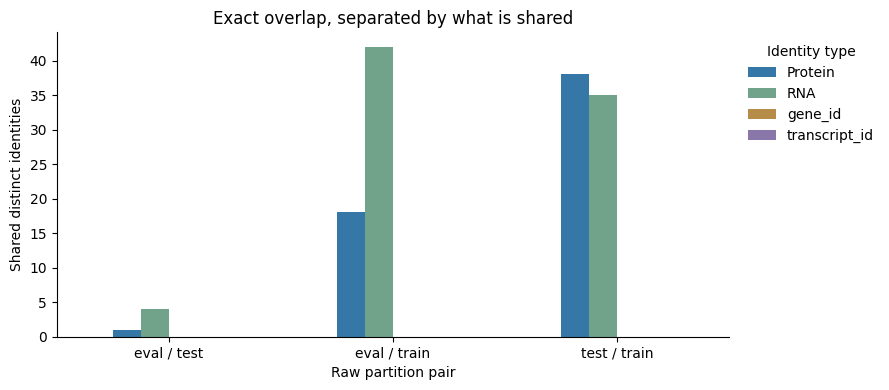

In [51]:
if data_checks is not None and not overlap_table.empty:
    overlap_plot = overlap_table.assign(
        pair=lambda frame: frame["split_a"] + " / " + frame["split_b"]
    ).pivot(index="pair", columns="identity", values="shared_unique_values")
    ax = overlap_plot.plot.bar(
        figsize=(9, 4), color=["#3578A8", "#71A38B", "#B68D48", "#8A77AA"],
        rot=0,
    )
    ax.set(xlabel="Raw partition pair", ylabel="Shared distinct identities",
           title="Exact overlap, separated by what is shared")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(title="Identity type", frameon=False, loc="upper left",
              bbox_to_anchor=(1.01, 1))
    ax.figure.tight_layout()
    plt.show()


**Interpretation.** Gene-separated and sequence-separated evaluation answer different questions. Different genes can supply the same protein, so a gene-disjoint split can still contain exact sequence matches. A nonzero overlap must be reconciled with the intended claim about unseen inputs, but does not alone prove target leakage or memorization. Zero exact matches do not establish separation of related sequences or gene families, and these checks do not compare extracted DNA windows.

These displays concern the raw partitions; repeat the relevant checks on the eventual retained and prepared inputs. Validation should support model selection separately from the final test evaluation. We next examine what each supplied sequence would present to an encoder.


---

## From sequence length to model input

After checking row meaning and partition separation, we ask what each retained sequence would present to an encoder. Biological length, unpadded token length and padded model input length are different quantities.

The RNA tokenizer uses six-nucleotide tokens, individual leftover bases and a leading CLS marker. For uninterrupted A/C/G/T sequence length `n`, the unpadded count is `1 + n // 6 + n % 6`; an N interrupts the sixmer run. Recognized protein characters use one token each plus CLS and EOS. Other symbols use the actual tokenizer. [Released tokenizer](https://huggingface.co/InstaDeepAI/isoformer/blob/afac2a386c8f2241faf8fad3c5971a9307c13775/isoformer_tokenizer.py).

**Worked examples.** A canonical 12,288-base RNA produces 2,049 tokens including CLS. A 1,000-residue protein produces 1,002 tokens, then 22 padding tokens reach the wrapper's 1,024-token target. A 1,200-residue protein produces 1,202 tokens and is not shortened by padding. The wrapper requests no truncation. The extra CLS token alone does not establish a model failure at 2,049; the [released-input trace](RUNBOOK.md#sequence-lengths-in-the-released-path) distinguishes reported context from demonstrated execution limits.

The helper checks fast counting against tokenizer fixtures and deterministic real-row positions. Every source row contributes to the totals; those checks validate counting rather than estimate totals from a sample.

In [52]:
length_rows = []
for key, label in (
    ("RNA_length", "RNA sequence characters"),
    ("Protein_length", "Protein sequence characters"),
    ("RNA_tokens", "RNA tokens including CLS"),
    ("Protein_tokens", "Protein tokens including CLS/EOS"),
):
    stats = audit["scopes"]["all"]["stats"][key]
    length_rows.append({
        "quantity": label,
        "nonmissing rows": stats["n"],
        "minimum": stats["min"],
        "maximum": stats["max"],
    })
display(pd.DataFrame(length_rows).set_index("quantity"))

,nonmissing rows,minimum,maximum
quantity,,,
RNA sequence characters,178215,41,205012
Protein sequence characters,91241,1,35991
RNA tokens including CLS,178215,9,34173
Protein tokens including CLS/EOS,91241,3,35993


### Is a limit affecting the bulk of the data or a long tail?

Means and maxima can hide very different length distributions. These fixed-bin counts make the population around the candidate limits visible. Intervals are categorical and have unequal widths; bar height is a row count, not a probability density. Missing strings are excluded from the bars and counted separately.


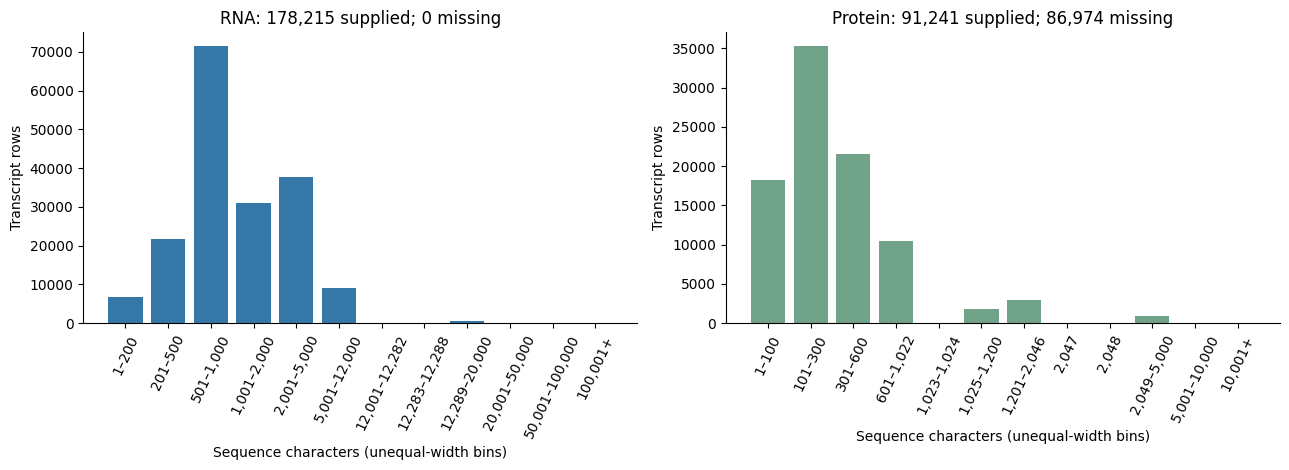

In [53]:
if data_checks is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, modality, color in zip(axes, ("RNA", "Protein"), ("#3578A8", "#71A38B")):
        distribution = data_checks["length_distributions"][modality]
        labels = []
        lower = 1
        for upper in distribution["upper_bounds"]:
            label = (f"{lower:,}+" if upper is None else
                     f"{upper:,}" if lower == upper else f"{lower:,}–{upper:,}")
            labels.append(label)
            if upper is not None:
                lower = upper + 1
        ax.bar(np.arange(len(labels)), distribution["counts"], color=color)
        ax.set(xticks=np.arange(len(labels)), xticklabels=labels,
               xlabel="Sequence characters (unequal-width bins)", ylabel="Transcript rows",
               title=(f"{modality}: {distribution['present']:,} supplied; "
                      f"{distribution['missing']:,} missing"))
        ax.tick_params(axis="x", labelrotation=65)
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    plt.show()
else:
    print("Length histograms were not recorded; the existing length summaries remain available.")


In [54]:
if data_checks is not None:
    # One longest recorded row per input, not full sequences or a new selection.
    examples = [
        {"selected for": modality, **row}
        for modality in ("RNA", "Protein")
        if (row := data_checks["representative_rows"][f"longest_{modality}"]) is not None
    ]
    display(pd.DataFrame(examples))


,selected for,Protein_length,Protein_tokens,RNA_length,RNA_tokens,annotation,cds_present,gene_id,protein_id_present,row_number,split,transcript_id
0,RNA,NaN,NaN,205012,34173,lnc_RNA,False,ENSG00000281344.1,False,11618,eval,ENST00000626826.1
1,Protein,35991.0,35993.0,109224,18205,mRNA,True,ENSG00000155657.26,True,110046,train,ENST00000589042.5


### How many rows would each limit affect?

The limits below come from different source statements: protein 2,047 in Table 1, 2,048 in §4.3, 1,200 in Table 6; RNA 12 kb in §4.3, 12,282 in Table 1 and 12,288 in Table 6. The 1,024-token check describes the released padding target, not an established maximum. [Paper, §4.3 and Tables 1, 6–7](https://proceedings.neurips.cc/paper_files/paper/2024/file/8f6b3692297e49e5d5c91ba00281379c-Paper-Conference.pdf).

Every number below counts rows **strictly greater than** its threshold. Protein-string lengths include supplied symbols such as `*`; no cleaning, exclusion or truncation is applied. The thresholds are alternatives and their counts overlap—they must not be added together.

In [55]:
limit_checks = [
    ("RNA", "sequence characters", 12_000, "RNA_length_gt_12000"),
    ("RNA", "sequence characters", 12_282, "RNA_length_gt_12282"),
    ("RNA", "sequence characters", 12_288, "RNA_length_gt_12288"),
    ("RNA", "tokens including markers", 1_024, "RNA_tokens_gt_1024"),
    ("RNA", "tokens including markers", 2_048, "RNA_tokens_gt_2048"),
    ("Protein", "sequence characters", 1_200, "Protein_length_gt_1200"),
    ("Protein", "sequence characters", 2_047, "Protein_length_gt_2047"),
    ("Protein", "sequence characters", 2_048, "Protein_length_gt_2048"),
    ("Protein", "tokens including markers", 1_024, "Protein_tokens_gt_1024"),
    ("Protein", "tokens including markers", 2_048, "Protein_tokens_gt_2048"),
]
limit_rows = []
for modality, unit, threshold, count_key in limit_checks:
    row = {"input": modality, "unit": unit, "limit exceeded": threshold}
    for label, scope_key in [("all", "all")] + [
        (split, f"split:{split}") for split in audit["splits"]
    ]:
        row[label] = audit["scopes"][scope_key]["counts"].get(count_key, 0)
    limit_rows.append(row)
display(pd.DataFrame(limit_rows).set_index(["input", "unit", "limit exceeded"]))

all  eval  test  train
input   unit                     limit exceeded                         
RNA     sequence characters      12000            603    49    25    529
                                 12282            556    44    19    493
                                 12288            555    44    19    492
        tokens including markers 1024            5503   316   261   4926
                                 2048             559    44    19    496
Protein sequence characters      1200            3884   224   153   3507
                                 2047             959    60    42    857
                                 2048             957    60    42    855
        tokens including markers 1024            5767   304   257   5206
                                 2048             960    60    42    858

**Interpretation.** Padding adds artificial tokens to reach a requested input length; cropping removes sequence content, while exclusion removes a transcript from the experiment. The released wrapper requests padding without truncation.

A small proportion of long proteins may still dominate memory or represent particular transcript groups. Keeping one requires a feasible encoder and batching path; cropping one changes its representation; excluding one changes the prediction population. These are the consequences to weigh alongside the affected-row counts.


### Are unusual symbols affecting the count?

This check preserves source spelling. Lowercase, U, whitespace and unsupported symbols are reported rather than silently normalized. The alphabet table identifies supplied characters; the fallback table counts rows handled by the actual tokenizer when the fast formula is inapplicable.

In [56]:
alphabet_rows = [
    {"input": modality, "character": repr(character), "occurrences": count}
    for modality, alphabet in audit["alphabets"].items()
    for character, count in sorted(alphabet.items())
]
display(pd.DataFrame(alphabet_rows).set_index(["input", "character"]))
display(pd.Series(
    audit["fallback_rows"], name="rows requiring actual-tokenizer fallback"
).to_frame())

occurrences
input   character             
Protein '*'                307
        'A'            2386125
        'C'             757949
        'D'            1659952
        'E'            2476055
        'F'            1241089
        'G'            2229207
        'H'             893335
        'I'            1498181
        'K'            2001029
        'L'            3395554
        'M'             762006
        'N'            1247767
        'P'            2146093
        'Q'            1649647
        'R'            1952113
        'S'            2870007
        'T'            1837514
        'U'                118
        'V'            2056382
        'W'             422651
        'X'               6844
        'Y'             908050
RNA     'A'           75841578
        'C'           70672660
        'G'           72135084
        'N'                  1
        'T'           71941283

,rows requiring actual-tokenizer fallback
Protein,59
RNA,0


### What would a 3′ RNA crop change?

The paper describes retaining the RNA 3′ end for untranslated-region context related to abundance. Here we ask what each proposed suffix width would do to the token counts. The suffixes are counting scenarios; the original CSV and uncropped summaries stay unchanged.

The distinction matters because a base limit does not guarantee a token limit. We count again after cropping rather than dividing length by six or assuming that fewer bases always produce fewer tokens.

In [57]:
crop_rows = []
all_counts = audit["scopes"]["all"]["counts"]
for width in (12_000, 12_282, 12_288):
    crop_rows.append({
        "RNA 3′ suffix retained (nt)": width,
        "rows shortened": all_counts.get(f"RNA_length_gt_{width}", 0),
        "still above 2,048 tokens": all_counts.get(
            f"RNA_after_3prime_{width}_tokens_gt_2048", 0
        ),
    })
display(pd.DataFrame(crop_rows).set_index("RNA 3′ suffix retained (nt)"))

,rows shortened,"still above 2,048 tokens"
RNA 3′ suffix retained (nt),,
12000,603,0
12282,556,3
12288,555,559


**Interpretation.** Compare two different counts: rows whose RNA is shortened by the suffix rule, and rows whose resulting token sequence still exceeds the stated budget. A zero in the latter column does not mean that no RNA was cropped or that no information was lost. The remaining 3′ sequence supplies a different input from the full transcript.

Fitting the token budget establishes compatibility with that counting rule, rather than identifying the authors' historical crop. The RNA-preparation decision remains open.


## Does genomic context change the eligible population?

The DNA input is a continuous genomic window around the transcript's transcription start site, not its spliced RNA. The official example requests 196,608 bases: 98,304 on either side of an anchor derived from the transcript coordinates, with reverse-complementing for negative-strand transcripts. The loader rejects boundary failures instead of adding N characters and explicitly excludes mitochondrial `chrMT` rows. [Released loader and window function](https://huggingface.co/datasets/InstaDeepAI/multi_omics_transcript_expression/blob/330ab1795abca683e692c7ee138a2e89c0c882f1/multi_omics_transcript_expression.py#L473).

The example also requests a second boundary filter. Its inspected arithmetic checks `[anchor - 196608, anchor)`, toward lower genomic coordinates on both strands; that is not necessarily biological upstream on a negative strand. Its historical training rationale is unresolved. Both checks use the released strict upper-bound rejection, including an interval ending exactly at the chromosome size. The audit evaluates these coordinate rules using chromosome sizes, without downloading or extracting the genome.

**Illustrative example.** With an anchor at coordinate 150,000 on a sufficiently long chromosome, the main window is `[51696, 248304)` and fits. The additional interval is `[-46608, 150000)` and fails because its start is negative. The row could therefore be excluded even with a short, supplied protein; this is a DNA-context decision, not a protein-length filter.

The disjoint summary attributes exclusions to mitochondrial rows, then main-window failure, then additional-filter failure. The release tests the additional filter first; attribution order differs, but the retained set is the same. These are example-derived scenarios, not the recovered historical training membership.


In [58]:
boundary = audit["scopes"]["example_boundary_policy"]
boundary_rows = []
for label, scope in (
    ("All raw rows", audit["scopes"]["all"]),
    ("Pass both example window checks", boundary),
):
    proteins = scope["stats"].get("Protein_length", {}).get("n", 0)
    boundary_rows.append({
        "scenario": label,
        "rows": scope["rows"],
        "protein supplied": proteins,
        "protein missing": scope["rows"] - proteins,
        "protein characters >2,048": scope["counts"].get("Protein_length_gt_2048", 0),
    })
display(pd.DataFrame(boundary_rows).set_index("scenario"))
display(pd.Series(
    audit["example_boundary_exclusions"], name="mutually exclusive exclusions"
).to_frame())

,rows,protein supplied,protein missing,"protein characters >2,048"
scenario,,,,
All raw rows,178215,91241,86974,957
Pass both example window checks,177693,91032,86661,957


,mutually exclusive exclusions
additional_shifted_filter,156
chrMT,37
main_window,329


**Interpretation.** The two tables separate how many rows pass both checks from the mutually exclusive reasons assigned to excluded rows. A failure means the requested DNA context fails these rules; it does not mean that the transcript or its RNA-expression target is biologically invalid.

Compare protein availability and length before and after the boundary checks. Passing them does not supply a missing protein or guarantee that a long protein is feasible to encode. Under the proposed missing-protein approach, DNA-eligible rows without a protein could still participate, subject to the remaining input rules. Whether to adopt both example window filters remains a cohort decision.


---
## Which populations would an input policy affect?

An overall percentage can conceal a disproportionate effect on one partition or transcript annotation. The following summaries combine earlier observations by raw split and annotation. They describe candidate rules on unchanged source rows, rather than selecting a training cohort.

**Reading the grouped table.** Missing protein uses all rows in that group as its denominator; overlength protein uses only supplied proteins; over-budget RNA uses supplied RNAs. A protein-length percentage shown as NaN when no proteins are supplied is undefined, not a measured zero. The DNA columns describe eligibility under the example's coordinate checks, not verified extraction or successful inference.

`RNA + protein supplied, DNA eligible` counts the intersection of those three conditions. It does not apply a complete training policy and does not count the proposed cohort that would also allow transcripts without proteins.


In [59]:
if data_checks is not None:
    policy_groups = data_checks["policy_impacts"]["groups"]
    policy_rows = []
    for group in policy_groups:
        reasons = group["reasons"]
        proteins, rnas = group["protein_present"], group["rna_present"]
        policy_rows.append({
            "raw split": group["split"],
            "raw annotation": group["annotation"],
            "rows": group["rows"],
            "protein missing (% of rows)": 100 * reasons["protein_missing"] / group["rows"],
            "protein >2,048 (% of supplied)": (
                100 * reasons["protein_length_gt_2048"] / proteins if proteins else None
            ),
            "RNA >2,048 tokens (% of supplied)": (
                100 * reasons["rna_tokens_gt_2048"] / rnas if rnas else None
            ),
            "DNA window eligible": group["dna_eligible"],
            "RNA + protein supplied, DNA eligible": group["all_three_present_after_boundary"],
        })
    policy_table = pd.DataFrame(policy_rows).set_index(["raw split", "raw annotation"])
    display(policy_table.round(2))
else:
    print("Policy effects by annotation and raw split were not recorded.")


rows  protein missing (% of rows)  \
raw split raw annotation                                       
eval      lnc_RNA          2890                        100.0   
          mRNA             4656                          0.0   
          miRNA             108                        100.0   
          rRNA                1                        100.0   
          scRNA               2                        100.0   
          snRNA              89                        100.0   
          snoRNA             45                        100.0   
          tRNA                1                        100.0   
          transcript       1328                        100.0   
test      lnc_RNA          2783                        100.0   
          mRNA             4363                          0.0   
          miRNA              89                        100.0   
          rRNA                6                        100.0   
          scRNA               2                        100.0   
          snRNA             100                        100.0   
          snoRNA             54                        100.0   
          tRNA                1                        100.0   
          transcript       1158                        100.0   
train     lnc_RNA         50556                        100.0   
          mRNA            82222                          0.0   
          miRNA            1680                        100.0   
          rRNA               41                        100.0   
          scRNA              46                        100.0   
          snRNA            1716                        100.0   
          snoRNA            842                        100.0   
          tRNA               20                        100.0   
          transcript      23416                        100.0   

                          protein >2,048 (% of supplied)  \
raw split raw annotation                                   
eval      lnc_RNA                                    NaN   
          mRNA                                      1.29   
          miRNA                                      NaN   
          rRNA                                       NaN   
          scRNA                                      NaN   
          snRNA                                      NaN   
          snoRNA                                     NaN   
          tRNA                                       NaN   
          transcript                                 NaN   
test      lnc_RNA                                    NaN   
          mRNA                                      0.96   
          miRNA                                      NaN   
          rRNA                                       NaN   
          scRNA                                      NaN   
          snRNA                                      NaN   
          snoRNA                                     NaN   
          tRNA                                       NaN   
          transcript                                 NaN   
train     lnc_RNA                                    NaN   
          mRNA                                      1.04   
          miRNA                                      NaN   
          rRNA                                       NaN   
          scRNA                                      NaN   
          snRNA                                      NaN   
          snoRNA                                     NaN   
          tRNA                                       NaN   
          transcript                                 NaN   

                          RNA >2,048 tokens (% of supplied)  \
raw split raw annotation                                      
eval      lnc_RNA                                      0.14   
          mRNA                                         0.84   
          miRNA                                        0.00   
          rRNA                                         0.00   
          scRNA                                    

**Reading the heatmap.** Every column below instead uses **all rows in its raw partition** as the denominator. Its overlength-protein percentage can therefore differ from the grouped table's percentage among supplied proteins. The plot summarizes how common each condition is in a partition, not what fraction a chosen policy has removed.

The color scale spans 0–100%, so small nonzero values can look almost white; read the printed percentages as well. “RNA after 12k crop >2,048 tokens” counts residual token-budget exceedances, not the number of RNAs cropped or the information lost.


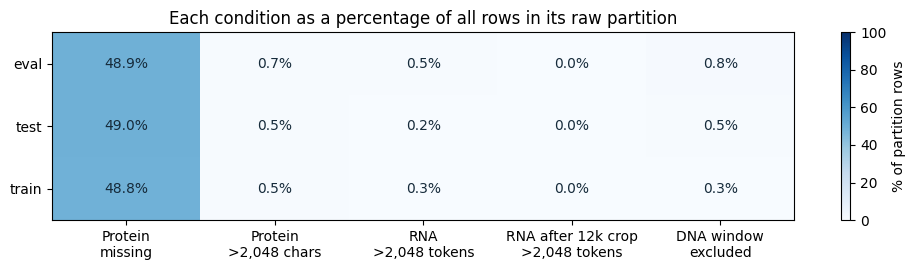

In [60]:
if data_checks is not None:
    # Use all rows within each partition here so every column shares its denominator.
    plotted_reasons = {
        "protein_missing": "Protein\nmissing",
        "protein_length_gt_2048": "Protein\n>2,048 chars",
        "rna_tokens_gt_2048": "RNA\n>2,048 tokens",
        "rna_after_3prime_12000_tokens_gt_2048": "RNA after 12k crop\n>2,048 tokens",
        "dna_boundary_excluded": "DNA window\nexcluded",
    }
    definitions = data_checks["policy_impacts"]["definitions"]
    plotted_reasons = {key: label for key, label in plotted_reasons.items()
                       if key in definitions}
    split_rates = []
    for split in sorted({group["split"] for group in policy_groups}):
        groups = [group for group in policy_groups if group["split"] == split]
        row_count = sum(group["rows"] for group in groups)
        split_rates.append({
            "raw split": split,
            **{label: 100 * sum(group["reasons"][key] for group in groups) / row_count
               for key, label in plotted_reasons.items()},
        })
    split_rates = pd.DataFrame(split_rates).set_index("raw split")
    fig, ax = plt.subplots(figsize=(10, max(2.8, len(split_rates) * 0.8)))
    colors = ax.imshow(split_rates.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
    for row in range(len(split_rates)):
        for column in range(len(split_rates.columns)):
            value = split_rates.iloc[row, column]
            ax.text(column, row, f"{value:.1f}%", ha="center", va="center",
                    color="white" if value > 55 else "#162B3B")
    ax.set(xticks=np.arange(len(split_rates.columns)), xticklabels=split_rates.columns,
           yticks=np.arange(len(split_rates)), yticklabels=split_rates.index,
           title="Each condition as a percentage of all rows in its raw partition")
    fig.colorbar(colors, ax=ax, label="% of partition rows")
    fig.tight_layout()
    plt.show()


### Do the reasons affect the same rows?

The percentages above are **not additive**. One transcript can lack a protein and fail a DNA boundary check, or exceed both a protein limit and an RNA token budget. For example, if 10 rows met one exclusion rule, 6 met another and 4 met both, their union would remove 12 rows, not 16. These illustrative counts are not notebook results.

The next table shows up to 20 nonzero annotation/partition/reason pairs, ordered by count; an omitted pair is not necessarily zero. The JSON retains the full recorded pair counts. Pairwise intersections do not identify every higher-order overlap, so a final combined selection must be specified explicitly. Saved example IDs are bounded examples for individual reasons, not verified examples of each displayed intersection.


In [61]:
if data_checks is not None:
    pairs = [
        {"raw split": group["split"], "raw annotation": group["annotation"],
         "overlapping reasons": pair, "rows": count}
        for group in policy_groups
        for pair, count in group["overlapping_reason_pairs"].items() if count
    ]
    pair_table = pd.DataFrame(pairs)
    if pair_table.empty:
        print("No pairwise reason overlaps were observed.")
    else:
        display(pair_table.sort_values("rows", ascending=False).head(20))
        print(f"Showing up to 20 of {len(pair_table)} nonzero group/reason pairs; "
              "the complete counts remain in the JSON.")
    display(pd.Series(data_checks["policy_impacts"]["definitions"],
                      name="Recorded reason definition").to_frame())
    display(pd.DataFrame(data_checks["representative_rows"]["missing_protein_examples"]))


,raw split,raw annotation,overlapping reasons,rows
112,train,lnc_RNA,protein_id_missing & protein_missing,50556
107,train,lnc_RNA,cds_missing & protein_missing,50556
106,train,lnc_RNA,cds_missing & protein_id_missing,50556
162,train,transcript,cds_missing & protein_missing,23416
161,train,transcript,cds_missing & protein_id_missing,23416
167,train,transcript,protein_id_missing & protein_missing,23416
2,eval,lnc_RNA,cds_missing & protein_missing,2890
7,eval,lnc_RNA,protein_id_missing & protein_missing,2890
1,eval,lnc_RNA,cds_missing & protein_id_missing,2890
60,test,lnc_RNA,cds_missing & protein_id_missing,2783


Showing up to 20 of 173 nonzero group/reason pairs; the complete counts remain in the JSON.


,Recorded reason definition
cds_missing,No CDS string supplied.
dna_boundary_excluded,Coordinates fail the inference example's chrom...
protein_id_missing,No associated Ensembl protein transcript ID su...
protein_length_gt_1200,"Supplied protein exceeds 1,200 characters."
protein_length_gt_2048,"Supplied protein exceeds 2,048 characters."
protein_missing,No protein string supplied; this does not esta...
rna_after_3prime_12000_tokens_gt_2048,"Hypothetical 12,000-character RNA suffix excee..."
rna_after_3prime_12282_tokens_gt_2048,"Hypothetical 12,282-character RNA suffix excee..."
rna_after_3prime_12288_tokens_gt_2048,"Hypothetical 12,288-character RNA suffix excee..."
rna_missing,No RNA string supplied under the exact missing...


,Protein_length,Protein_tokens,RNA_length,RNA_tokens,annotation,cds_present,gene_id,protein_id_present,row_number,split,transcript_id
0,None,None,1657,278,lnc_RNA,False,ENSG00000223972.5,False,1,train,ENST00000456328.2
1,None,None,712,123,lnc_RNA,False,ENSG00000243485.5,False,2,train,ENST00000473358.1
2,None,None,535,91,lnc_RNA,False,ENSG00000243485.5,False,3,train,ENST00000469289.1
3,None,None,1187,203,lnc_RNA,False,ENSG00000237613.2,False,4,train,ENST00000417324.1
4,None,None,590,101,lnc_RNA,False,ENSG00000237613.2,False,5,train,ENST00000461467.1


**Interpretation.** Evaluate an exclusion by both its count and the transcript populations it removes. Protein, CDS and associated-identifier absence may describe the same rows; summing those reasons would count them repeatedly. The tables can help prioritize a small set of alternatives for discussion with Mina without treating every combination as a separate experiment.

Missing-protein handling, RNA cropping and long-protein batching remain separate choices. In particular, the missing-protein rates measure absent source information, not the number that must be excluded under the proposed zero-contribution approach.


## Compare with the earlier local audit

This reference is an **earlier local calculation**, not the authors' experiment. The code compares aggregate counts available in both records: row and identity totals, raw partitions, sequence availability, threshold exceedances and RNA-crop token counts, across the common scopes.

The original script recognized missing markers case-insensitively; the reusable helper recognizes lowercase markers exactly and preserves biological strings such as `NAN`. Agreement here would show no effect on the compared counts for this source.

Saving uses a stricter check: the complete audit identity and measurements must match, ignoring only declared execution-provenance fields. A fresh execution time alone does not create another JSON or replace the earlier producer.


In [62]:
def comparable_counts(result):
    values = {
        "rows": result["row_count"],
        "unique IDs": result["unique_transcript_ids"],
        "duplicate IDs": result["duplicate_transcript_ids"],
    }
    for split, count in result["splits"].items():
        values[f"split:{split}:rows"] = count
    # Compare the shared scenarios; the older audit also had a chrMT-only view.
    scope_names = ["all", "example_boundary_policy"] + [
        name for split in result["splits"]
        for name in (f"split:{split}", f"example_boundary_policy:{split}")
    ]
    for scope_name in scope_names:
        scope = result["scopes"].get(scope_name)
        if scope is None:
            values[f"{scope_name}:rows"] = None
            continue
        values[f"{scope_name}:rows"] = scope["rows"]
        for stat in ("RNA_length", "Protein_length", "RNA_tokens", "Protein_tokens"):
            values[f"{scope_name}:{stat}:n"] = scope["stats"].get(stat, {}).get("n", 0)
        for _, _, _, key in limit_checks:
            values[f"{scope_name}:{key}"] = scope["counts"].get(key, 0)
        for width in (12_000, 12_282, 12_288):
            key = f"RNA_after_3prime_{width}_tokens_gt_2048"
            values[f"{scope_name}:{key}"] = scope["counts"].get(key, 0)
    return values


if selected_path == HISTORICAL_RECORD:
    print("Displaying the historical reference; no separate notebook result is selected.")
elif not HISTORICAL_RECORD.exists():
    print("Historical reference is unavailable; the selected result remains readable.")
else:
    recorded_audit = cohort.read_audit(
        HISTORICAL_RECORD, expected_identity=LEGACY_IDENTITY, allow_legacy=True
    )
    expected = comparable_counts(recorded_audit)
    observed = comparable_counts(audit)
    differences = pd.DataFrame([
        {"measurement": key, "historical": expected.get(key), "selected": observed.get(key)}
        for key in sorted(expected.keys() | observed.keys())
        if expected.get(key) != observed.get(key)
    ])
    print(f"{len(differences)} count discrepancies; neither record was modified.")
    if not differences.empty:
        display(differences)

0 count discrepancies; neither record was modified.


**Interpretation.** No reported discrepancies means the selected aggregate counts agree for the verified input identities. That supports consistency of the local counting workflow. This comparison does not cover the newer annotation, target, overlap and grouped-policy checks, or establish identical row membership, equality of the full reports or the authors' training population.


---
## What must be agreed before training?

The audit connects the source rows, targets, supplied inputs, partitions and preparation rules so that cohort decisions have measurable consequences.

### Already agreed reference behavior

Retain the released Enformer-based reference, DNA pooling interval `765:770` and `released_unmasked` protein fusion behavior. Omitting the protein padding mask during fusion for supplied proteins is separate from the proposed whole-modality absence rule. The [reproduction notebook](tier2_isoformer_reproduction.ipynb#Settings-and-deliberate-boundaries) explains how these recorded decisions relate to its current settings; the [reference specification](RUNBOOK.md#released-computation-and-proposed-notebook) retains their source limitations.


### Proposed population and missing-protein handling

**Proposed by the assistant for review; not yet adopted or implemented:** retain both protein-supplied and protein-absent transcripts that satisfy the eventual agreed input rules, using the zero-contribution mechanism explained above for absent proteins. An earlier protein-supplied-first suggestion limited the initial work to the available released path. The revised recommendation follows the paper's broader transcript task and missing-modality description.

The proposed comparisons would share validation/test transcript IDs wherever their inputs support the same population, with overall scores and scores separated by protein availability. A protein-only model requires the supplied-protein subset; compare it with other models on that same subset. This preserves a useful diagnostic comparison without defining the broader task only around coding transcripts.


### Choices that still need agreement

| Choice | What this audit contributes | What remains to agree |
| --- | --- | --- |
| Cohort and missing proteins | Availability, exact source annotations, mapping fields and DNA eligibility. | Whether to adopt the proposed absent-protein path and which coordinate/input rules define eligibility; how unresolved annotation or mapping cases are handled. |
| RNA preparation | Separate source limits, full-input token counts and 3′-crop scenarios. | Released handling or a declared paper-based crop, with an explicit base/token rule. |
| Long proteins and batching | Length distributions and the groups each threshold affects. | A feasible batching policy and any justified crop or exclusion; no automatic truncation follows from the padding target. |
| Validation and test | Raw identities and exact-sequence overlaps; the loader's test alias. | Validation selection from training, its unit and membership, and matched evaluated populations. |
| Target preparation | Tissue order and stored-label checks. | Any further normalization and its source; a second log or an inferred normalization is not justified by these plots. |
| Training protocol | Links to the unresolved source-to-setting specification. | Trainer settings where the sources remain incomplete, precision, stopping and resource accommodations; these are not determined by a data audit. |

The reproduction notebook tracks [implementation prerequisites](tier2_isoformer_reproduction.ipynb#What-is-ready,-and-what-remains?) separately from these scientific decisions.

For discussion with Mina, each consequential choice should identify the **paper statement, GitHub example, pinned Hugging Face behavior, local implementation, remaining uncertainty and compute consequence**. The per-method slide deck should show these distinctions before expensive runs. Repeat seeds belong in the later run/cost plan after the primary protocol is agreed.

This preparation supports `Gantt`/`Details` tasks **44** and **28**; task 44's recorded scope still describes the earlier pilot.


### Evidence and implementation route

- [Audit execution records](../../docs/run-records.md#2026-11-09-gtex-full-csv-length-and-token-audit): historical source identity, calculation and verification.
- [Result directory](results/isoformer_cohort_audit/): the preserved historical JSON and any completed notebook result. The notebook reads the named path, not the newest file.
- [Counting and storage helper](../shared_code/fusion/isoformer_cohort.py), [GTEx data checks](../shared_code/fusion/isoformer_data_checks.py) and [synthetic checks](../../tests/test_isoformer_cohort.py): inspect counting, boundary checks and result publication without research data.
- [Sources](../../docs/sources.md#isoformer-dataset-and-model-cards) and [reference specification](RUNBOOK.md#sequence-lengths-in-the-released-path): source discrepancies and unresolved reconstruction choices.

Execution dates and producer details belong to the selected JSON. Saved notebook displays retain the provenance of the execution that produced them.